
## Executive Summary

- Duka Electronics recorded **1,000 orders** between January and June 2026, generating total revenue of **KES 71,792,500**.
- Nairobi was the highest-performing branch, generating **KES 26,106,100 from 376 orders**, while Eldoret recorded the lowest branch revenue at KES 8,844,200.
- Laptops generated the highest product revenue, while Tablets led in units sold, demonstrating a difference between revenue contribution and sales volume.
- Weekdays accounted for **72.23% of total revenue**, compared with 27.77% generated on weekends, although weekend average order revenue was slightly higher at KES 71,972.20.
- April was the strongest month, generating **KES 13,518,300**, while June was the weakest at KES 10,903,400, representing a 23.98% revenue difference relative to June.



# Duka Electronics Sales Exploration

**Assignment:** PLP Data Analytics – Assignment 3

**Engagement:** Duka Electronics

**Period:** January – June 2026

**Objective:** Explore sales performance, identify business trends and provide actionable insights for the leadership team.


In [1]:
!git clone https://github.com/gloriaokeyo18-stack/plp-da-a3-duka-sales-and-agent-cleanup.git

Cloning into 'plp-da-a3-duka-sales-and-agent-cleanup'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [2]:
%cd plp-da-a3-duka-sales-and-agent-cleanup


/content/plp-da-a3-duka-sales-and-agent-cleanup


In [3]:
!ls

generate_data.py


In [5]:
!python generate_data.py

In [6]:
!ls -lh *.csv

-rw-r--r-- 1 root root 517 Nov 24 18:43 agents.csv
-rw-r--r-- 1 root root 25K Nov 24 18:43 agent_transactions.csv
-rw-r--r-- 1 root root 47K Nov 24 18:43 duka_sales.csv


Inspecting the data

In [7]:
import pandas as pd

# Load the three datasets
sales = pd.read_csv("duka_sales.csv")
agents = pd.read_csv("agents.csv")
txns = pd.read_csv("agent_transactions.csv")

# Display dataset dimensions
print("DUKA SALES:", sales.shape)
print("AGENTS:", agents.shape)
print("AGENT TRANSACTIONS:", txns.shape)

DUKA SALES: (1000, 7)
AGENTS: (20, 3)
AGENT TRANSACTIONS: (612, 5)


To give a quick visual confirmation that the datasets contain the expected columns and records:

In [8]:
display(sales.head())
display(agents.head())
display(txns.head())

,order_id,order_date,branch,product,quantity,channel,unit_price
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500


,agent_id,county,onboarded
0,AG001,Mombasa,2024-01-01
1,AG002,Nairobi,2024-02-01
2,AG003,Kisumu,2024-03-01
3,AG004,Kiambu,2024-04-01
4,AG005,Mombasa,2024-05-01


,txn_id,agent_id,txn_type,amount,txn_date
0,TX00001,AG009,deposit,353.0,2026-03-03
1,TX00002,AG020,deposit,1238.0,2026-04-27
2,TX00003,AG008,DEPOSIT,9129.0,2026-04-29
3,TX00004,AG009,deposit,652.0,2026-04-24
4,TX00005,AG009,withdrawal,478.0,2026-04-17



## 1. Data Loading and Initial Inspection

### Objective
Load the Duka Electronics sales dataset and conduct an initial inspection to understand its structure, data types, completeness, date coverage and key categorical variables.

This first-five-minutes inspection will help identify potential data-quality concerns and establish the dataset's suitability for further analysis.


In [9]:

# Import required libraries
import pandas as pd
import numpy as np

# Load the sales dataset with correct date parsing
sales = pd.read_csv(
    "duka_sales.csv",
    parse_dates=["order_date"]
)

# Display the first five records
sales.head()


,order_id,order_date,branch,product,quantity,channel,unit_price
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500


In [10]:
# Check the number of rows and columns
print("Dataset dimensions:", sales.shape)
print("Number of orders:", sales.shape[0])
print("Number of columns:", sales.shape[1])

Dataset dimensions: (1000, 7)
Number of orders: 1000
Number of columns: 7


In [11]:
# Examine column names and data types
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   order_id    1000 non-null   int64         
 1   order_date  1000 non-null   datetime64[ns]
 2   branch      1000 non-null   object        
 3   product     1000 non-null   object        
 4   quantity    1000 non-null   int64         
 5   channel     1000 non-null   object        
 6   unit_price  1000 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 54.8+ KB


In [12]:
# Count missing values in each column
sales.isnull().sum()

,0
order_id,0
order_date,0
branch,0
product,0
quantity,0
channel,0
unit_price,0


In [13]:
# Identify the earliest and latest order dates
print("Earliest order:", sales["order_date"].min())
print("Latest order:", sales["order_date"].max())

Earliest order: 2026-01-01 00:00:00
Latest order: 2026-06-29 00:00:00


In [14]:
# Examine the unique values in categorical columns
print("Branches:", sales["branch"].unique())
print("\nProducts:", sales["product"].unique())
print("\nSales channels:", sales["channel"].unique())

# Examine the frequency of each category
print("\nOrders by branch:")
print(sales["branch"].value_counts())

print("\nOrders by product:")
print(sales["product"].value_counts())

print("\nOrders by channel:")
print(sales["channel"].value_counts())

Branches: ['Nakuru' 'Nairobi' 'Mombasa' 'Eldoret' 'Kisumu']

Products: ['Phone' 'Laptop' 'Tablet' 'Headphones' 'Charger']

Sales channels: ['In-store' 'Online' 'Phone order']

Orders by branch:
branch
Nairobi    376
Mombasa    186
Nakuru     162
Kisumu     159
Eldoret    117
Name: count, dtype: int64

Orders by product:
product
Laptop        220
Tablet        215
Phone         194
Headphones    187
Charger       184
Name: count, dtype: int64

Orders by channel:
channel
In-store       579
Online         320
Phone order    101
Name: count, dtype: int64



### First-Five-Minutes Inspection Findings

The Duka Electronics dataset contains **1,000 orders and 7 columns**, representing sales transactions recorded between 1 January and 29 June 2026.

**1. Dataset structure and data types**

The dataset contains three numerical columns (`order_id`, `quantity`, and `unit_price`), three categorical columns (`branch`, `product`, and `channel`), and one datetime column (`order_date`). The date column was correctly parsed as datetime64 during data loading.

**2. Data completeness**

All seven columns contain 1,000 non-null values. No missing values were identified during the initial inspection, indicating that the dataset is complete with respect to the available fields.

**3. Date coverage**

The earliest recorded order is 1 January 2026, while the latest is 29 June 2026. The dataset therefore covers the January–June 2026 review period.

**4. Key categorical variables**

The dataset contains five branches: Nairobi, Mombasa, Nakuru, Kisumu and Eldoret. Nairobi accounts for the highest number of orders (376), followed by Mombasa (186), while Eldoret has the fewest (117).

Five products are represented: Laptop (220 orders), Tablet (215), Phone (194), Headphones (187) and Charger (184).

Three sales channels are present: In-store (579 orders), Online (320 orders) and Phone order (101 orders). In-store is the most frequently used channel.

**5. Initial assessment**

The dataset has a consistent structure, correctly interpreted data types and no missing values. It is suitable for further exploration, including revenue calculations, branch comparisons, product performance analysis and temporal sales trends.



## 2. Data Preparation and Derived Columns

To support the sales analysis, five derived columns will be created.

- **Revenue:** Calculated by multiplying quantity by unit price.
- **Month:** Extracted from the order date to support monthly comparisons.
- **Weekday:** Extracted as the name of the day on which the order occurred.
- **Is_weekend:** Identifies Saturday and Sunday orders.
- **Price_band:** Classifies products with a unit price of KES 28,000 or more as Premium, while products below this threshold are classified as Value.


In [15]:

# Calculate revenue for each order
sales["revenue"] = sales["quantity"] * sales["unit_price"]

# Extract month from order_date
sales["month"] = sales["order_date"].dt.month_name()

# Extract weekday
sales["weekday"] = sales["order_date"].dt.day_name()

# Identify weekend orders (Saturday = 5, Sunday = 6)
sales["is_weekend"] = sales["order_date"].dt.dayofweek >= 5

# Classify products by price band
sales["price_band"] = np.where(
    sales["unit_price"] >= 28000,
    "Premium",
    "Value"
)

# Inspect the transformed dataset
sales.head()


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue,month,weekday,is_weekend,price_band
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000,June,Wednesday,False,Value
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000,February,Monday,False,Premium
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000,January,Monday,False,Premium
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500,12500,April,Sunday,True,Value
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500,7500,March,Saturday,True,Value


In [16]:
# Check the new columns and their data types
print(sales[[
    "revenue",
    "month",
    "weekday",
    "is_weekend",
    "price_band"
]].head())

print("\nPrice band distribution:")
print(sales["price_band"].value_counts())

print("\nWeekend distribution:")
print(sales["is_weekend"].value_counts())

   revenue     month    weekday  is_weekend price_band
0    45000      June  Wednesday       False      Value
1   260000  February     Monday       False    Premium
2   140000   January     Monday       False    Premium
3    12500     April     Sunday        True      Value
4     7500     March   Saturday        True      Value

Price band distribution:
price_band
Value      565
Premium    435
Name: count, dtype: int64

Weekend distribution:
is_weekend
False    723
True     277
Name: count, dtype: int64



## 3. Branch Performance: Revenue vs Order Volume

This analysis ranks the five branches using two performance indicators: total revenue and the number of orders processed.

The comparison will establish whether branches with the highest sales volume also generate the highest revenue. Differences between the rankings may reflect variations in product mix, selling prices and quantities purchased.


In [17]:

# Aggregate sales by branch
branch_summary = sales.groupby("branch").agg(
    total_revenue=("revenue", "sum"),
    number_of_orders=("order_id", "nunique")
).reset_index()

# Rank branches by total revenue
branch_summary["revenue_rank"] = (
    branch_summary["total_revenue"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Rank branches by number of orders
branch_summary["order_rank"] = (
    branch_summary["number_of_orders"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Display results, ordered by revenue
branch_summary = branch_summary.sort_values(
    "revenue_rank"
).reset_index(drop=True)

display(branch_summary)


,branch,total_revenue,number_of_orders,revenue_rank,order_rank
0,Nairobi,26106100,376,1,1
1,Mombasa,14003700,186,2,2
2,Nakuru,11970400,162,3,3
3,Kisumu,10868100,159,4,4
4,Eldoret,8844200,117,5,5


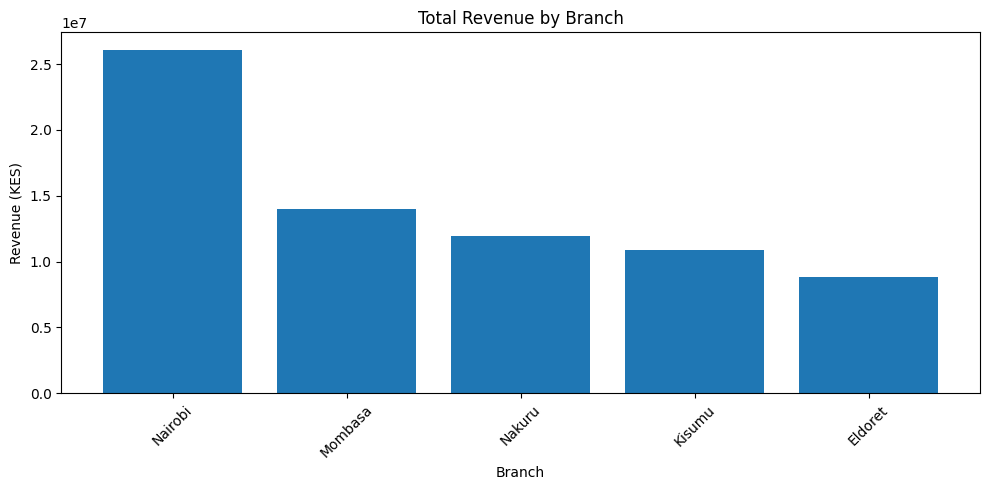

In [18]:
import matplotlib.pyplot as plt

# Revenue comparison
plt.figure(figsize=(10, 5))

plt.bar(
    branch_summary["branch"],
    branch_summary["total_revenue"]
)

plt.title("Total Revenue by Branch")
plt.xlabel("Branch")
plt.ylabel("Revenue (KES)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Findings and Business Interpretation

Nairobi is the leading branch in both revenue and order volume, generating KES 26,106,100 from 376 orders. Mombasa ranks second with KES 14,003,700 from 186 orders, while Nakuru, Kisumu and Eldoret occupy the third, fourth and fifth positions respectively.

The revenue and order-volume rankings are identical across all five branches. This suggests that, within this dataset, branches handling more orders also generate higher total revenue.

However, identical rankings do not necessarily mean that the branches generate the same revenue per order. Differences in product mix, quantities purchased and average transaction values may still exist.

**Business implication:** Nairobi represents the largest sales contributor and should remain a priority when allocating inventory and operational resources. Management should also investigate the factors supporting its higher sales volume to identify practices that could be replicated in other branches.


In [19]:
branch_summary["average_revenue_per_order"] = (
    branch_summary["total_revenue"] /
    branch_summary["number_of_orders"]
).round(2)

display(branch_summary)

,branch,total_revenue,number_of_orders,revenue_rank,order_rank,average_revenue_per_order
0,Nairobi,26106100,376,1,1,69431.12
1,Mombasa,14003700,186,2,2,75288.71
2,Nakuru,11970400,162,3,3,73891.36
3,Kisumu,10868100,159,4,4,68352.83
4,Eldoret,8844200,117,5,5,75591.45



## 4. Product Performance Analysis

This section evaluates product performance using two indicators: total revenue generated and total units sold.

Comparing these indicators will help identify whether the products generating the highest sales value are also the products with the greatest sales volume.


In [20]:

# Summarise sales by product
product_summary = sales.groupby("product").agg(
    total_revenue=("revenue", "sum"),
    units_sold=("quantity", "sum"),
    number_of_orders=("order_id", "nunique")
).reset_index()

# Rank products by revenue
product_by_revenue = product_summary.sort_values(
    "total_revenue", ascending=False
).reset_index(drop=True)

# Rank products by units sold
product_by_units = product_summary.sort_values(
    "units_sold", ascending=False
).reset_index(drop=True)

print("TOP PRODUCTS BY REVENUE")
display(product_by_revenue.head(3))

print("TOP PRODUCTS BY UNITS SOLD")
display(product_by_units.head(3))


TOP PRODUCTS BY REVENUE


,product,total_revenue,units_sold,number_of_orders
0,Laptop,41535000,639,220
1,Tablet,19348000,691,215
2,Phone,8880000,592,194


TOP PRODUCTS BY UNITS SOLD


,product,total_revenue,units_sold,number_of_orders
0,Tablet,19348000,691,215
1,Laptop,41535000,639,220
2,Phone,8880000,592,194


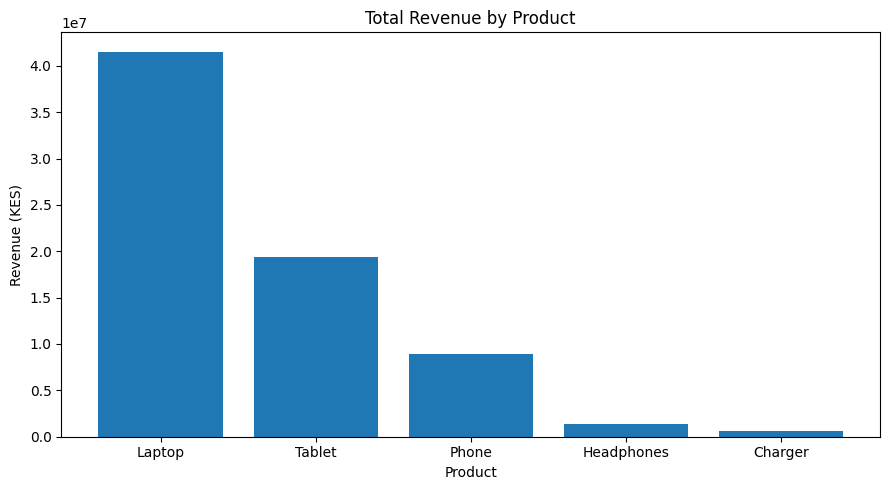

In [21]:
# Product revenue comparison
plt.figure(figsize=(9, 5))

plt.bar(
    product_by_revenue["product"],
    product_by_revenue["total_revenue"]
)

plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (KES)")
plt.tight_layout()
plt.show()

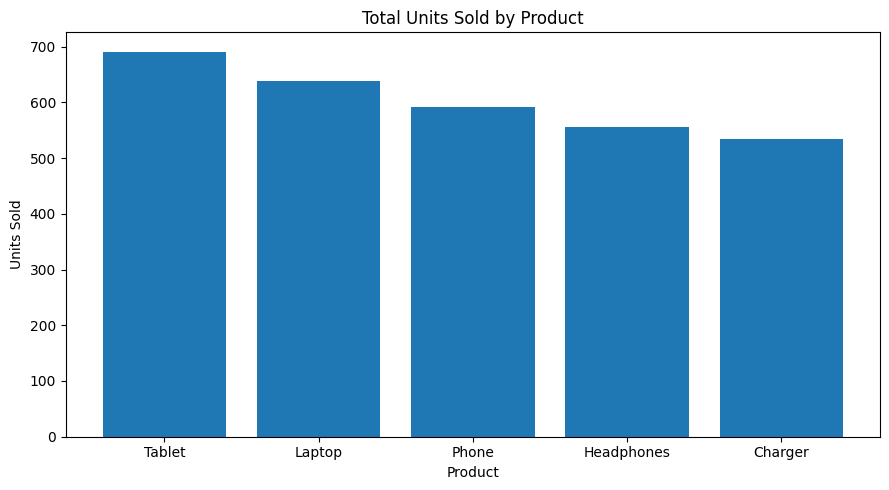

In [22]:
# Product units sold comparison
plt.figure(figsize=(9, 5))

plt.bar(
    product_by_units["product"],
    product_by_units["units_sold"]
)

plt.title("Total Units Sold by Product")
plt.xlabel("Product")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()


### Findings and Business Interpretation

Laptops are the highest revenue-generating product, followed by Tablets, Phones, Headphones and Chargers. However, the ranking by units sold differs, with Tablets leading in sales volume.

This difference demonstrates that sales volume and revenue contribution are not interchangeable measures of product performance. Laptops have a higher unit price of KES 65,000 compared with KES 28,000 for Tablets. Consequently, laptop sales generate more revenue even though Tablets sell in greater quantities.

**Business implication:** Duka Electronics should consider both sales volume and revenue when making inventory and purchasing decisions. High-volume products require adequate stock availability, while high-revenue products deserve attention because of their contribution to overall sales value.



## 5. Weekend vs Weekday Sales Performance

This analysis compares sales recorded on weekdays (Monday–Friday) and weekends (Saturday–Sunday).

The comparison uses order volume, total revenue and average revenue per order to establish whether weekend and weekday purchasing patterns differ.


In [23]:

# Group sales by weekend status
weekend_summary = sales.groupby("is_weekend").agg(
    number_of_orders=("order_id", "nunique"),
    total_revenue=("revenue", "sum"),
    average_order_revenue=("revenue", "mean")
).reset_index()

# Replace Boolean values with readable labels
weekend_summary["day_type"] = weekend_summary[
    "is_weekend"
].map({
    False: "Weekday",
    True: "Weekend"
})

# Arrange columns for presentation
weekend_summary = weekend_summary[
    [
        "day_type",
        "number_of_orders",
        "total_revenue",
        "average_order_revenue"
    ]
]

display(weekend_summary.round(2))


,day_type,number_of_orders,total_revenue,average_order_revenue
0,Weekday,723,51856200,71723.65
1,Weekend,277,19936300,71972.20


In [24]:
total_sales_revenue = sales["revenue"].sum()

weekend_summary["revenue_share_pct"] = (
    weekend_summary["total_revenue"] /
    total_sales_revenue * 100
).round(2)

display(weekend_summary)

,day_type,number_of_orders,total_revenue,average_order_revenue,revenue_share_pct
0,Weekday,723,51856200,71723.651452,72.23
1,Weekend,277,19936300,71972.202166,27.77



### Findings and Business Interpretation

Weekdays account for 723 orders (72.3% of all orders), generating KES 51,856,200 in revenue, equivalent to 72.23% of total sales revenue. Weekends account for 277 orders (27.7%), generating KES 19,936,300, or 27.77% of total revenue.

Despite the difference in order volume, average revenue per order is marginally higher on weekends (KES 71,972.20) than on weekdays (KES 71,723.65). The difference is approximately KES 248.55 per order.

These findings suggest that Duka Electronics generates most of its revenue through weekday sales volume, while weekend orders have a slightly higher average value.

**Business implication:** Management should maintain sufficient staffing and inventory during weekdays to support higher order volumes. Weekend promotions could also be explored to increase customer traffic while preserving the slightly higher average order value observed during this period.



## 6. Monthly Revenue Performance

This section examines monthly revenue trends between January and June 2026 to identify the strongest and weakest sales months.

The percentage difference between the highest- and lowest-performing months will also be calculated to quantify the variation in monthly revenue.


In [25]:

# Define the correct calendar order
month_order = [
    "January", "February", "March",
    "April", "May", "June"
]

# Summarise revenue and order volume by month
monthly_summary = sales.groupby("month").agg(
    total_revenue=("revenue", "sum"),
    number_of_orders=("order_id", "nunique")
).reindex(month_order).reset_index()

display(monthly_summary)


,month,total_revenue,number_of_orders
0,January,11786600,173
1,February,11772000,159
2,March,12396800,186
3,April,13518300,167
4,May,11415400,153
5,June,10903400,162


In [26]:
best_month = monthly_summary.loc[
    monthly_summary["total_revenue"].idxmax()
]

worst_month = monthly_summary.loc[
    monthly_summary["total_revenue"].idxmin()
]

percentage_difference = (
    (best_month["total_revenue"] - worst_month["total_revenue"])
    / worst_month["total_revenue"]
) * 100

print("Highest revenue month:", best_month["month"])
print("Highest monthly revenue: KES", best_month["total_revenue"])

print("\nLowest revenue month:", worst_month["month"])
print("Lowest monthly revenue: KES", worst_month["total_revenue"])

print(
    "\nPercentage difference:",
    round(percentage_difference, 2), "%"
)

Highest revenue month: April
Highest monthly revenue: KES 13518300

Lowest revenue month: June
Lowest monthly revenue: KES 10903400

Percentage difference: 23.98 %



### Findings and Business Interpretation

April recorded the highest monthly revenue at KES 13,518,300 from 167 orders, while June recorded the lowest revenue at KES 10,903,400 from 162 orders.

The difference between the highest- and lowest-performing months was KES 2,614,900. April's revenue was approximately 23.98% higher than June's revenue, using June's revenue as the reference value.

Interestingly, April generated the highest revenue despite having fewer orders than January and March. This suggests that order volume alone does not explain monthly revenue performance; differences in quantities purchased and product mix may also contribute.

June's lower revenue, despite recording more orders than May, similarly suggests that the value of individual transactions may have influenced monthly performance.

**Business implication:** Management should investigate the product mix, quantities sold and average order values that contributed to April's stronger performance. The decline in revenue towards June also warrants further investigation before making inventory or promotional decisions.



## 7. Premium Online Orders: Nairobi and Mombasa

This section filters the sales dataset to identify Premium orders placed through the Online channel in the Nairobi and Mombasa branches.

The resulting subset will be exported as a CSV file for further use and reporting.


In [27]:

# Filter Premium Online orders from Nairobi and Mombasa
premium_online_coast_capital = sales[
    (sales["price_band"] == "Premium") &
    (sales["channel"] == "Online") &
    (sales["branch"].isin(["Nairobi", "Mombasa"]))
].copy()

# Display the filtered records
display(premium_online_coast_capital.head())

# Report the number of qualifying orders and their revenue
print("Number of qualifying orders:",
      len(premium_online_coast_capital))

print("Total revenue (KES):",
      premium_online_coast_capital["revenue"].sum())


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue,month,weekday,is_weekend,price_band
6,1007,2026-01-15,Nairobi,Laptop,2,Online,65000,130000,January,Thursday,False,Premium
13,1014,2026-06-12,Nairobi,Tablet,3,Online,28000,84000,June,Friday,False,Premium
32,1033,2026-04-29,Nairobi,Laptop,2,Online,65000,130000,April,Wednesday,False,Premium
35,1036,2026-03-02,Nairobi,Laptop,4,Online,65000,260000,March,Monday,False,Premium
39,1040,2026-02-10,Mombasa,Laptop,5,Online,65000,325000,February,Tuesday,False,Premium


Number of qualifying orders: 83
Total revenue (KES): 10218000


Exporting the CSV:

In [28]:
from pathlib import Path

Path("outputs").mkdir(exist_ok=True)

In [29]:
premium_online_coast_capital.to_csv(
    "outputs/premium_online_coast_capital.csv",
    index=False
)

print("CSV exported successfully.")

CSV exported successfully.


In [30]:
# Verify the exported CSV
exported_data = pd.read_csv(
    "outputs/premium_online_coast_capital.csv"
)

print("Exported file shape:", exported_data.shape)
print("Number of records:", len(exported_data))

print("\nBranch distribution:")
print(exported_data["branch"].value_counts())

print("\nChannel distribution:")
print(exported_data["channel"].value_counts())

print("\nPrice band distribution:")
print(exported_data["price_band"].value_counts())

Exported file shape: (83, 12)
Number of records: 83

Branch distribution:
branch
Nairobi    50
Mombasa    33
Name: count, dtype: int64

Channel distribution:
channel
Online    83
Name: count, dtype: int64

Price band distribution:
price_band
Premium    83
Name: count, dtype: int64


Preparing the Excel folder and data:

In [31]:
from pathlib import Path

Path("excel").mkdir(exist_ok=True)

In [32]:
# Export the complete sales dataset for Excel analysis
sales.to_csv("excel/duka_sales_data.csv", index=False)

print("Excel source data prepared.")

Excel source data prepared.


In [33]:
from google.colab import files

files.download("excel/duka_sales_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
print("Notebook total revenue (KES):", sales["revenue"].sum())

Notebook total revenue (KES): 71792500


In [35]:
from google.colab import files

uploaded = files.upload()

Saving Duka Electronics Sales Analysis.xlsx to Duka Electronics Sales Analysis.xlsx


In [36]:
import shutil

shutil.move(
    "duka_branch_summary.xlsx",
    "excel/duka_branch_summary.xlsx"
)

print("Excel workbook saved successfully.")

FileNotFoundError: [Errno 2] No such file or directory: 'duka_branch_summary.xlsx'

In [37]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

print("\nFiles in excel folder:")
print(os.listdir("excel"))

Current working directory:
/content/plp-da-a3-duka-sales-and-agent-cleanup

Files in current directory:
['agent_transactions.csv', 'duka_sales.csv', 'excel', 'generate_data.py', '.git', 'outputs', 'agents.csv', 'Duka Electronics Sales Analysis.xlsx']

Files in excel folder:
['duka_sales_data.csv']


In [38]:
import shutil
from pathlib import Path

filename = list(uploaded.keys())[0]

destination = Path("excel") / "duka_branch_summary.xlsx"

shutil.move(filename, destination)

print("Workbook saved:", destination.exists())
print("File size:", destination.stat().st_size, "bytes")

Workbook saved: True
File size: 133366 bytes


In [39]:
import os

print("Repository contents:")
for root, dirs, files in os.walk("."):
    # Ignore Git's internal directory
    dirs[:] = [d for d in dirs if d != ".git"]

    level = root.count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Repository contents:
./
    agent_transactions.csv
    duka_sales.csv
    generate_data.py
    agents.csv
    excel/
        duka_sales_data.csv
        duka_branch_summary.xlsx
    outputs/
        premium_online_coast_capital.csv


In [40]:
!git status --short

?? agent_transactions.csv
?? agents.csv
?? duka_sales.csv
?? excel/
?? outputs/


In [41]:
%%writefile .gitignore
# Generated raw datasets
/duka_sales.csv
/agents.csv
/agent_transactions.csv

# Temporary Excel source data
/excel/duka_sales_data.csv

# Python cache files
__pycache__/
*.pyc

# Environment files
.env

Writing .gitignore


In [42]:
!git ls-files

generate_data.py


In [43]:
!pwd
!git remote -v

/content/plp-da-a3-duka-sales-and-agent-cleanup
origin	https://github.com/gloriaokeyo18-stack/plp-da-a3-duka-sales-and-agent-cleanup.git (fetch)
origin	https://github.com/gloriaokeyo18-stack/plp-da-a3-duka-sales-and-agent-cleanup.git (push)
